# 9. Natural convection

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1 and 7

In Chapter 7 a wind or a pump drove the fluid past the surface. Often nothing drives it:
air next to a warm wall is heated, becomes lighter than the air around it, and rises. The
rising layer is a boundary layer like those of Chapter 7, but its velocity is set by the
temperature difference itself. Heat transfer of this kind, *natural* or *free*
convection, is weak, with coefficients of a few W/(m² K) in air, and it is often all there
is.

Two problems show what it decides. An outdoor cabinet of telecom electronics in Astana is
sealed against dust and rain and has no fan: how much power can it dissipate in a 35 °C
summer afternoon before its walls exceed 50 °C? And on a calm winter night the wind of
Chapters 1 and 7 is gone: how much heat does the district-heating pipe lose then? The
laminar layer on a vertical plate has an exact similarity solution, found by Ostrach in
1953; it is computed here by shooting, checked by collocation and by a marching solution
that does not assume similarity, and used to test the correlations of Churchill and Chu
on which the engineering calculations rest.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

try:
    from engtransport import convection_ext, natural_conv, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import convection_ext, natural_conv, properties, reference
from engtransport.constants import SIGMA_SB
from engtransport.plotting import panel_label, use_style

use_style()
g = 9.81                     # m/s2

## 9.1 Buoyancy and the boundary layer

Take a vertical plate at temperature $T_w$ in still fluid at $T_\infty$, with $x$ measured
upwards from the lower edge and $y$ out from the plate. The density changes with
temperature by only a few per cent, and the *Boussinesq approximation* keeps that change
only where it matters, in the weight of the fluid: $\rho = \rho_\infty[1 - \beta(T -
T_\infty)]$, with the expansion coefficient $\beta = 1/T$ for an ideal gas. The pressure
outside the layer is hydrostatic, so the net upward force on unit volume is
$\rho_\infty g\beta(T - T_\infty)$, and the boundary-layer equations of Chapter 7 become

$$
\frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} = 0 , \qquad
u\frac{\partial u}{\partial x} + v\frac{\partial u}{\partial y}
= \nu\frac{\partial^2 u}{\partial y^2} + g\beta\,(T - T_\infty) , \qquad
u\frac{\partial T}{\partial x} + v\frac{\partial T}{\partial y}
= \alpha\frac{\partial^2 T}{\partial y^2} ,
\tag{9.1}
$$

with $u = v = 0$ and $T = T_w$ at the plate, and $u \to 0$, $T \to T_\infty$ far from it.
The flow and the heat transfer are now coupled: without a temperature difference there is
no flow.

The sizes follow from balancing the terms. In a layer of thickness $\delta$ at height $x$,
inertia $u^2/x$ and friction $\nu u/\delta^2$ both balance the buoyancy
$g\beta\Delta T$, with $\Delta T = T_w - T_\infty$. Inertia against buoyancy gives
$u \sim (g\beta\Delta T x)^{1/2}$, the speed a body gains falling through $x$ under the
reduced gravity $g\beta\Delta T$; friction against buoyancy then gives

$$
\frac{\delta}{x} \sim \mathrm{Gr}_x^{-1/4} , \qquad
\mathrm{Nu}_x = \frac{h x}{k} \sim \mathrm{Gr}_x^{1/4} , \qquad
\mathrm{Gr}_x = \frac{g\beta\,\Delta T\,x^3}{\nu^2} , \qquad
\mathrm{Ra}_x = \mathrm{Gr}_x\,\mathrm{Pr} ,
\tag{9.2}
$$

for Prandtl numbers near 1. The *Grashof number* plays the part of $\mathrm{Re}^2$ in
forced convection, and the *Rayleigh number* $\mathrm{Ra}$ is what experiments are
correlated in. Since $h \propto x^{-1/4}$, the coefficient varies only weakly with
height, and a tall wall transfers almost as much per square metre as a short one.

## 9.2 The similarity solution

Ostrach (1953) found that the profiles at all heights have the same shape when the
distance from the wall is measured in units of the local thickness. With

$$
\eta = \frac{y}{x}\left(\frac{\mathrm{Gr}_x}{4}\right)^{1/4} , \qquad
\psi = 4\nu\left(\frac{\mathrm{Gr}_x}{4}\right)^{1/4} F(\eta) , \qquad
\theta = \frac{T - T_\infty}{T_w - T_\infty} ,
$$

where $u = \partial\psi/\partial y$ and $v = -\partial\psi/\partial x$ satisfy continuity,
Eqs. (9.1) reduce to two ordinary differential equations,

$$
F''' + 3FF'' - 2F'^2 + \theta = 0 , \qquad \theta'' + 3\,\mathrm{Pr}\,F\theta' = 0 ,
\tag{9.3}
$$

with $F = F' = 0$ and $\theta = 1$ at $\eta = 0$, and $F' \to 0$, $\theta \to 0$ as
$\eta \to \infty$. The velocity is $u = (2\nu/x)\,\mathrm{Gr}_x^{1/2} F'(\eta)$. Since the
heat flux is $-k\,\partial T/\partial y$ at the wall,

$$
\mathrm{Nu}_x = G(\mathrm{Pr})\left(\frac{\mathrm{Gr}_x}{4}\right)^{1/4} , \qquad
\overline{\mathrm{Nu}}_L = \frac{4}{3}\,G(\mathrm{Pr})\left(\frac{\mathrm{Gr}_L}{4}\right)^{1/4} ,
\tag{9.4}
$$

where $G = -\theta'(0)$, and the mean over a height $L$ is $4/3$ of the local value at the
top because $h \propto x^{-1/4}$.

The two unknown wall values, $F''(0)$ and $G$, are found by *shooting*: guess them,
integrate Eqs. (9.3) outwards with the Runge–Kutta method, and correct the guesses by
Newton's method until $F'$ and $\theta$ vanish at the edge of the domain. The equations
have solutions that grow exponentially away from the wall, which amplify small errors in
the guesses; `natural_conv.free_convection_similarity` therefore lengthens the domain in
steps of one unit, each solved from the previous answer.

In [2]:
Prs_profiles = (0.72, 7.0, 100.0)
sim = {Pr: natural_conv.free_convection_similarity(Pr) for Pr in Prs_profiles}
for Pr in (0.1, 0.72, 2.0, 7.0, 20.0, 100.0):
    s = sim[Pr] if Pr in sim else natural_conv.free_convection_similarity(Pr)
    i = int(np.argmax(s["Fp"]))
    print(f"Pr = {Pr:6.2f}: F''(0) = {s['fpp0']:.5f}, G = -theta'(0) = {s['G']:.5f}, "
          f"Nu_x / Gr_x^(1/4) = {s['G'] / math.sqrt(2):.4f}; largest F' = {s['Fp'][i]:.4f} at eta = {s['eta'][i]:.2f}")
G_large = reference.free_convection_limits()["large_Pr"]
print(f"large-Pr limit: G = {G_large:.4f} Pr^(1/4), that is Nu_x = {G_large / math.sqrt(2):.4f} (Gr_x Pr)^(1/4)")

Pr =   0.10: F''(0) = 0.85917, G = -theta'(0) = 0.23015, Nu_x / Gr_x^(1/4) = 0.1627; largest F' = 0.4336 at eta = 1.20
Pr =   0.72: F''(0) = 0.67602, G = -theta'(0) = 0.50463, Nu_x / Gr_x^(1/4) = 0.3568; largest F' = 0.2762 at eta = 0.96


Pr =   2.00: F''(0) = 0.57126, G = -theta'(0) = 0.71647, Nu_x / Gr_x^(1/4) = 0.5066; largest F' = 0.2028 at eta = 0.85
Pr =   7.00: F''(0) = 0.45078, G = -theta'(0) = 1.05431, Nu_x / Gr_x^(1/4) = 0.7455; largest F' = 0.1314 at eta = 0.73


Pr =  20.00: F''(0) = 0.36196, G = -theta'(0) = 1.42155, Nu_x / Gr_x^(1/4) = 1.0052; largest F' = 0.0876 at eta = 0.64
Pr = 100.00: F''(0) = 0.25169, G = -theta'(0) = 2.19137, Nu_x / Gr_x^(1/4) = 1.5495; largest F' = 0.0442 at eta = 0.50
large-Pr limit: G = 0.7110 Pr^(1/4), that is Nu_x = 0.5027 (Gr_x Pr)^(1/4)


For air, $G = 0.5046$: $\mathrm{Nu}_x = 0.357\,\mathrm{Gr}_x^{1/4}$. As the Prandtl number
grows, the thermal layer becomes thin compared with the velocity layer, which is dragged
along by the buoyant fluid near the wall over a much greater thickness. In the limit
$\mathrm{Pr} \to \infty$ inertia drops out of the thin thermal layer; rescaling Eqs. (9.3)
for that limit (`reference.free_convection_limits`) gives

$$
\mathrm{Nu}_x \to 0.503\,(\mathrm{Gr}_x\mathrm{Pr})^{1/4} = 0.503\,\mathrm{Ra}_x^{1/4}
\quad (\mathrm{Pr} \to \infty) , \qquad
\mathrm{Nu}_x \propto (\mathrm{Gr}_x\mathrm{Pr}^2)^{1/4} \quad (\mathrm{Pr} \to 0) .
\tag{9.5}
$$

For viscous liquids the Rayleigh number alone decides the heat transfer; for liquid
metals viscosity drops out instead, and $\mathrm{Gr}\,\mathrm{Pr}^2$ decides it. Air and
water lie in between, 23 % and 9 % below the large-Pr limit.

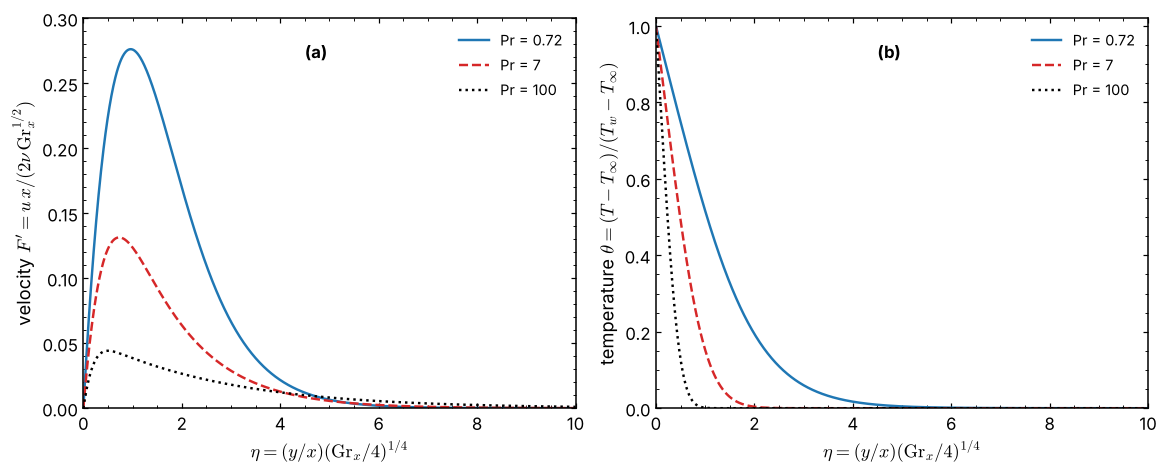

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
styles = {0.72: "C0-", 7.0: "C3--", 100.0: "k:"}
for Pr in Prs_profiles:
    s = sim[Pr]
    ax1.plot(s["eta"], s["Fp"], styles[Pr], label=f"Pr = {Pr:g}")
    ax2.plot(s["eta"], s["theta"], styles[Pr], label=f"Pr = {Pr:g}")
for ax in (ax1, ax2):
    ax.set_xlim(0, 10)
    ax.set_xlabel(r"$\eta = (y/x)(\mathrm{Gr}_x/4)^{1/4}$")
ax1.set_ylim(0, 0.3)
ax2.set_ylim(0, 1.02)
ax1.set_ylabel(r"velocity $F' = u\,x / (2\nu\,\mathrm{Gr}_x^{1/2})$")
ax2.set_ylabel(r"temperature $\theta = (T - T_\infty)/(T_w - T_\infty)$")
ax1.legend(loc="upper right")
ax2.legend(loc="upper right")
panel_label(ax1, "(a)", x=0.45, y=0.94)
panel_label(ax2, "(b)", x=0.45, y=0.94)
plt.show()

**Figure 9.1.** Ostrach's similarity solution for an isothermal vertical plate. (a) Velocity
and (b) temperature profiles for air ($\mathrm{Pr} = 0.72$), water ($\mathrm{Pr} = 7$) and
an oil ($\mathrm{Pr} = 100$). The velocity is zero at the wall and far away, with a maximum
inside the thermal layer; at large Pr the velocity layer extends far beyond the thin
thermal layer.

## 9.3 Correlations

The similarity solution holds while the layer is laminar. Above
$\mathrm{Ra}_L \approx 10^9$ the layer on a vertical plate becomes turbulent, and the heat
transfer grows faster with height. Churchill and Chu (1975) fitted one formula to
measurements over the whole range,

$$
\overline{\mathrm{Nu}}_L = \left\{0.825 +
\frac{0.387\,\mathrm{Ra}_L^{1/6}}{\left[1 + (0.492/\mathrm{Pr})^{9/16}\right]^{8/27}}\right\}^2 ,
\tag{9.6}
$$

and a more accurate one for the laminar range, $\mathrm{Ra}_L < 10^9$,

$$
\overline{\mathrm{Nu}}_L = 0.68 +
\frac{0.670\,\mathrm{Ra}_L^{1/4}}{\left[1 + (0.492/\mathrm{Pr})^{9/16}\right]^{4/9}} .
\tag{9.7}
$$

The second term of Eq. (9.7) is the similarity result (9.4) in a form that interpolates
between the limits (9.5); the constant 0.68 adds the heat conducted around the edges at
small Rayleigh numbers, where the layer is no longer thin. The same authors gave, for a
horizontal cylinder of diameter $D$ ($\mathrm{Ra}_D \le 10^{12}$),

$$
\overline{\mathrm{Nu}}_D = \left\{0.60 +
\frac{0.387\,\mathrm{Ra}_D^{1/6}}{\left[1 + (0.559/\mathrm{Pr})^{9/16}\right]^{8/27}}\right\}^2 .
\tag{9.8}
$$

On the upper face of a hot horizontal plate the warm fluid rises from the middle in a plume
rather than along the surface. Lloyd and Moran (1974) correlated their measurements with
the length $L = A/P$, area over perimeter:

$$
\overline{\mathrm{Nu}}_L = 0.54\,\mathrm{Ra}_L^{1/4} \quad (\mathrm{Ra}_L < 8 \times 10^6) ,
\qquad
\overline{\mathrm{Nu}}_L = 0.15\,\mathrm{Ra}_L^{1/3} \quad (8 \times 10^6 < \mathrm{Ra}_L < 1.6 \times 10^9) .
\tag{9.9}
$$

In the turbulent range $h$ no longer depends on the length: $\mathrm{Nu} \propto
\mathrm{Ra}^{1/3} \propto L$. Properties are taken at the film temperature, the mean of the
surface and the fluid.

## 9.4 A sealed electronics cabinet

The cabinet stands in the open: steel, 1.6 m high with a base of 0.6 × 0.6 m, painted with
a grey of emissivity 0.9. It is sealed, so all the heat of the electronics leaves through
its walls, by natural convection from the four sides and the top, and by radiation to the
surroundings, taken here at the air temperature (the sun is added in Exercise 1). With the
walls at a uniform $T_w$,

$$
\dot Q = \left(A_s\bar h_s + A_t\bar h_t\right)(T_w - T_\infty)
+ \varepsilon\sigma(A_s + A_t)\left(T_w^4 - T_{sur}^4\right) ,
\tag{9.10}
$$

where $\bar h_s$ follows from Eq. (9.6) with $L = 1.6$ m and $\bar h_t$ from Eq. (9.9).

In [4]:
H_cab, W_cab, D_cab, eps_cab = 1.6, 0.6, 0.6, 0.9
A_side = 2 * (W_cab + D_cab) * H_cab
A_top = W_cab * D_cab
L_top = A_top / (2 * (W_cab + D_cab))


def rayleigh(T_s, T_inf, L):
    air = properties.dry_air_properties(0.5 * (T_s + T_inf))
    return g * air["beta"] * abs(T_s - T_inf) * L**3 / (air["nu"] * air["alpha"]), air


def h_vertical(T_s, T_inf, L, laminar=False):
    Ra, air = rayleigh(T_s, T_inf, L)
    if laminar:
        return natural_conv.nu_vertical_plate_churchill_chu_laminar(Ra, air["Pr"]) * air["k"] / L
    return natural_conv.nu_vertical_plate_churchill_chu(Ra, air["Pr"]) * air["k"] / L


def h_top(T_s, T_inf):
    Ra, air = rayleigh(T_s, T_inf, L_top)
    return natural_conv.nu_horizontal_plate_up_lloyd_moran(Ra) * air["k"] / L_top


def cabinet(T_w, T_inf, eps=eps_cab, T_sur=None):
    """Heat flows (W) from the cabinet walls at T_w, Eq. (9.10)."""
    T_sur = T_inf if T_sur is None else T_sur
    q_side = A_side * h_vertical(T_w, T_inf, H_cab) * (T_w - T_inf)
    q_top = A_top * h_top(T_w, T_inf) * (T_w - T_inf)
    q_rad = (A_side + A_top) * eps * SIGMA_SB * (T_w**4 - T_sur**4)
    return {"side": q_side, "top": q_top, "rad": q_rad, "total": q_side + q_top + q_rad}


T_air, T_wall = 273.15 + 35.0, 273.15 + 50.0
Ra_side, air_film = rayleigh(T_wall, T_air, H_cab)
Ra_top, _ = rayleigh(T_wall, T_air, L_top)
c = cabinet(T_wall, T_air)
h_r = eps_cab * SIGMA_SB * (T_wall**4 - T_air**4) / (T_wall - T_air)
print(f"film {0.5 * (T_wall + T_air) - 273.15:.1f} C: Pr = {air_film['Pr']:.3f}; Ra = {Ra_side:.2e} (sides), {Ra_top:.2e} (top, L = {L_top:.2f} m)")
print(f"h: sides {h_vertical(T_wall, T_air, H_cab):.2f} (laminar formula {h_vertical(T_wall, T_air, H_cab, laminar=True):.2f}), "
      f"top {h_top(T_wall, T_air):.2f}, radiation {h_r:.2f} W/(m2 K)")
print(f"walls at 50 C in 35 C air: sides {c['side']:.0f} W, top {c['top']:.0f} W, radiation {c['rad']:.0f} W;"
      f" total {c['total']:.0f} W ({100 * c['rad'] / c['total']:.0f} % by radiation)")
x_tr = H_cab * (1e9 / Ra_side) ** (1 / 3)
print(f"the layer reaches Ra_x = 1e9 at a height of {x_tr:.2f} m")
for T_a in (20.0, 30.0, 40.0):
    print(f"air at {T_a:.0f} C: {cabinet(T_wall, 273.15 + T_a)['total']:.0f} W")
print(f"unpainted galvanised steel, eps = 0.25: {cabinet(T_wall, T_air, eps=0.25)['total']:.0f} W")

film 42.5 C: Pr = 0.705; Ra = 4.53e+09 (sides), 3.73e+06 (top, L = 0.15 m)
h: sides 3.38 (laminar formula 2.31), top 4.36, radiation 6.42 W/(m2 K)
walls at 50 C in 35 C air: sides 195 W, top 24 W, radiation 405 W; total 623 W (65 % by radiation)
the layer reaches Ra_x = 1e9 at a height of 0.97 m
air at 20 C: 1305 W
air at 30 C: 846 W
air at 40 C: 404 W
unpainted galvanised steel, eps = 0.25: 331 W


With its walls at 50 °C the cabinet can shed 620 W in 35 °C air. Two thirds of it leaves by
radiation: the radiation coefficient of a painted surface, 6.4 W/(m² K), is about twice
the convective one, 3.4 W/(m² K). This is typical of natural convection in air, and it is
why the colour of the paint in the infrared, not the convection correlation, is the first
thing to get right; bare galvanised steel would shed only about half as much.

The side walls have $\mathrm{Ra} = 4.5 \times 10^9$, so the layer turns turbulent about a
metre up, and the laminar formula (9.7) would underestimate $h$ by a third. The allowable
power falls by about 45 W for each degree of air temperature, because the wall-to-air
difference is only 15 K: at 40 °C it is 400 W, at 20 °C 1300 W.

## 9.5 The district-heating pipe on a calm night

The insulated pipe of Chapter 1 lost 63.7 W/m with $h = 25$ W/(m² K), which Chapter 7
showed to be a 6 m/s wind. On a calm night only natural convection, Eq. (9.8), and
radiation remain. The heat transfer coefficient now depends on the surface temperature,
which is solved for from the balance of Chapter 1:

In [5]:
r_w, r_ins, k_ins, eps_pipe, T_water = 0.05715, 0.10715, 0.045, 0.9, 273.15 + 110.0
T_cold = 273.15 - 35.0
R_ins = math.log(r_ins / r_w) / (2 * math.pi * k_ins)


def h_cylinder(T_s, T_inf, D):
    Ra, air = rayleigh(T_s, T_inf, D)
    return natural_conv.nu_horizontal_cylinder_churchill_chu(Ra, air["Pr"]) * air["k"] / D


def h_wind(V, D, T_s, T_inf):
    air = properties.dry_air_properties(0.5 * (T_s + T_inf))
    return convection_ext.nu_cylinder_churchill_bernstein(V * D / air["nu"], air["Pr"]) * air["k"] / D


def pipe_loss(V=0.0, insulated=True):
    """Heat loss (W/m) and surface temperature; V = 0 is natural convection alone,
    otherwise the larger of the forced and natural coefficients is used."""
    D = 2 * r_ins if insulated else 2 * r_w

    def out(T_s):
        h = h_cylinder(T_s, T_cold, D)
        if V > 0:
            h = max(h, h_wind(V, D, T_s, T_cold))
        return math.pi * D * (h * (T_s - T_cold) + eps_pipe * SIGMA_SB * (T_s**4 - T_cold**4)), h

    if not insulated:
        q, h = out(T_water)
        return q, T_water, h
    T_s = brentq(lambda T: (T_water - T) / R_ins - out(T)[0], T_cold + 1e-6, T_water)
    q, h = out(T_s)
    return q, T_s, h


q_ins, Ts_ins, h_ins = pipe_loss()
q_bare, _, h_bare = pipe_loss(insulated=False)
print(f"insulated pipe, calm: surface {Ts_ins - 273.15:.1f} C, h = {h_ins:.2f} W/(m2 K), loss {q_ins:.1f} W/m"
      f" ({100 * (q_ins / 63.7 - 1):+.1f} % against Chapter 1)")
print(f"bare pipe, calm: h = {h_bare:.2f} W/(m2 K), loss {q_bare:.0f} W/m (Chapter 1, h = 25: 1638 W/m)")
for D, name in ((2 * r_ins, "insulated"), (2 * r_w, "bare")):
    T_s = Ts_ins if name == "insulated" else T_water
    V_eq = brentq(lambda V: h_wind(V, D, T_s, T_cold) - h_cylinder(T_s, T_cold, D), 1e-3, 10.0)
    print(f"{name}: a wind of {V_eq:.2f} m/s gives the same h as natural convection")

insulated pipe, calm: surface -22.4 C, h = 4.05 W/(m2 K), loss 59.6 W/m (-6.5 % against Chapter 1)
bare pipe, calm: h = 7.88 W/(m2 K), loss 746 W/m (Chapter 1, h = 25: 1638 W/m)
insulated: a wind of 0.28 m/s gives the same h as natural convection
bare: a wind of 0.60 m/s gives the same h as natural convection


On a calm night the insulated pipe loses 59.6 W/m, 6.5 % less than in the wind, and its
cladding is 13 K warmer than the air instead of 3 K: the outer film now matters a little,
but the insulation still dominates. The bare pipe loses 746 W/m, less than half its loss in
the 6 m/s wind. Natural convection gives the same $h$ as a breeze of a few tenths of a
metre per second (computed above), so the wind takes over at speeds that are almost always
present outdoors; on a calm night, though, the bare pipe's loss is set by radiation and
natural convection in roughly equal parts.

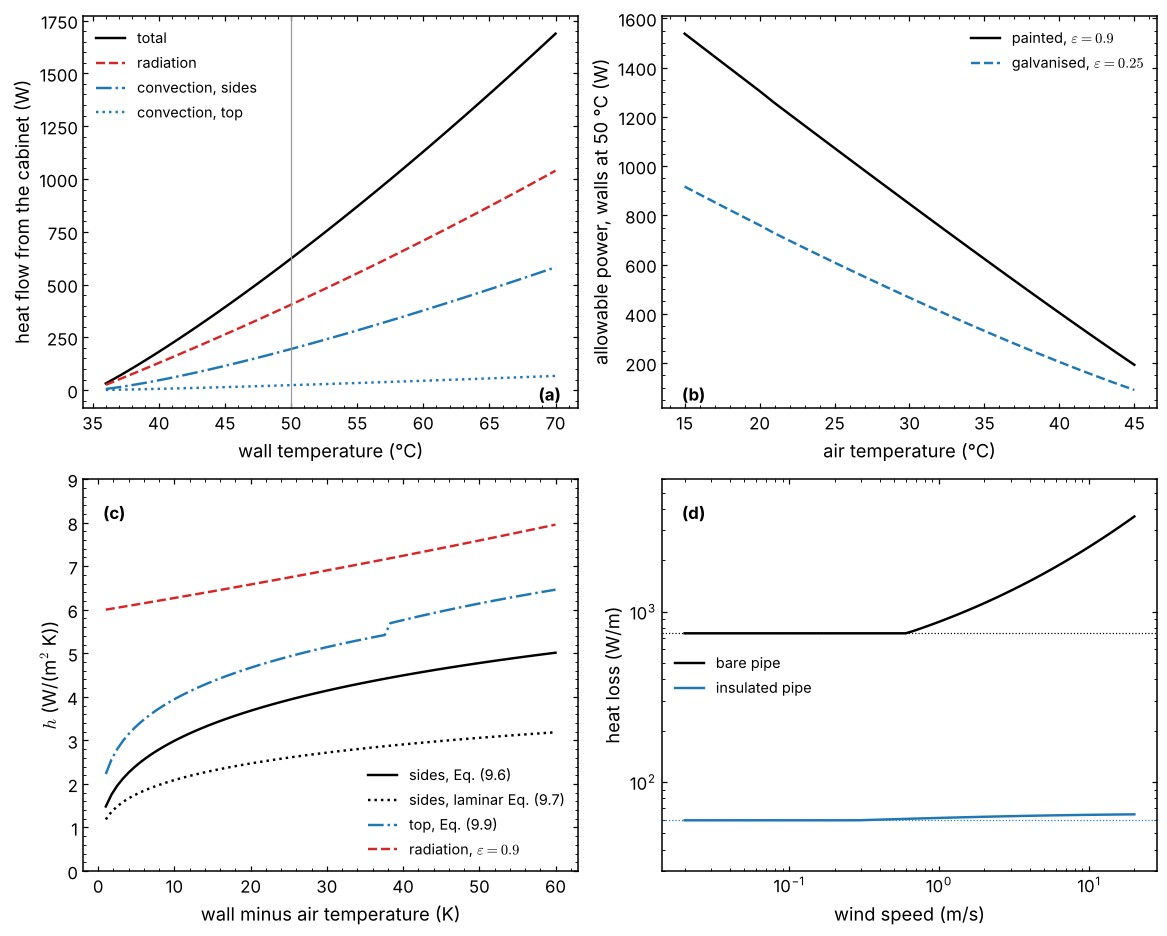

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

T_ws = 273.15 + np.linspace(36.0, 70.0, 60)
flows = [cabinet(T, T_air) for T in T_ws]
ax1.plot(T_ws - 273.15, [f["total"] for f in flows], "k-", label="total")
ax1.plot(T_ws - 273.15, [f["rad"] for f in flows], "C3--", label="radiation")
ax1.plot(T_ws - 273.15, [f["side"] for f in flows], "C0-.", label="convection, sides")
ax1.plot(T_ws - 273.15, [f["top"] for f in flows], "C0:", label="convection, top")
ax1.axvline(50.0, color="0.6", lw=0.8)
ax1.set_xlabel("wall temperature (°C)")
ax1.set_ylabel("heat flow from the cabinet (W)")
ax1.legend(loc="upper left")
panel_label(ax1, "(a)", x=0.92, y=0.06)

T_as = np.linspace(15.0, 45.0, 31)
for eps, style, label in ((0.9, "k-", r"painted, $\varepsilon = 0.9$"), (0.25, "C0--", r"galvanised, $\varepsilon = 0.25$")):
    ax2.plot(T_as, [cabinet(T_wall, 273.15 + Ta, eps=eps)["total"] for Ta in T_as], style, label=label)
ax2.set_xlabel("air temperature (°C)")
ax2.set_ylabel("allowable power, walls at 50 °C (W)")
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", x=0.04, y=0.06)

dTs = np.linspace(1.0, 60.0, 80)
ax3.plot(dTs, [h_vertical(T_air + d, T_air, H_cab) for d in dTs], "k-", label="sides, Eq. (9.6)")
ax3.plot(dTs, [h_vertical(T_air + d, T_air, H_cab, laminar=True) for d in dTs], "k:", label="sides, laminar Eq. (9.7)")
ax3.plot(dTs, [h_top(T_air + d, T_air) for d in dTs], "C0-.", label="top, Eq. (9.9)")
ax3.plot(dTs, [eps_cab * SIGMA_SB * ((T_air + d)**4 - T_air**4) / d for d in dTs], "C3--", label=r"radiation, $\varepsilon = 0.9$")
ax3.set_xlabel(r"wall minus air temperature (K)")
ax3.set_ylabel(r"$h$ (W/(m$^2$ K))")
ax3.set_ylim(0, 9)
ax3.legend(loc="lower right")
panel_label(ax3, "(c)", x=0.04, y=0.94)

Vs = np.geomspace(0.02, 20.0, 60)
ax4.loglog(Vs, [pipe_loss(V, insulated=False)[0] for V in Vs], "k-", label="bare pipe")
ax4.loglog(Vs, [pipe_loss(V)[0] for V in Vs], "C0-", label="insulated pipe")
ax4.axhline(q_bare, color="k", ls=":", lw=0.8)
ax4.axhline(q_ins, color="C0", ls=":", lw=0.8)
ax4.set_xlabel("wind speed (m/s)")
ax4.set_ylabel("heat loss (W/m)")
ax4.set_ylim(30, 6000)
ax4.legend(loc="center left")
panel_label(ax4, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 9.2.** (a) Heat flows from the sealed cabinet in 35 °C air against its wall
temperature, Eq. (9.10); the grey line marks the 50 °C limit. (b) Power the cabinet can
dissipate with its walls at 50 °C, against the air temperature, for a painted and a bare
galvanised surface. (c) Heat transfer coefficients on the cabinet: convection on the sides
(full-range and laminar formulas) and on the top, where the step marks the change of form
in Eq. (9.9), and the radiation coefficient. (d) Heat
loss of the district-heating pipe in −35 °C air against the wind speed, taking the larger
of the forced, Eq. (7.8), and natural, Eq. (9.8), coefficients; dotted lines are the calm
values.

## 9.6 Checks

Three checks test the similarity solution and the correlations built on it.

**Collocation.** `reference.free_convection_bvp` solves Eqs. (9.3) by collocation
(`scipy.integrate.solve_bvp`) on a long domain, with no shooting and no growing solutions
to control.

**Marching without similarity.** Written in the coordinates $\xi = x/L$ and the $\eta$ of
Section 9.2, with $\psi = 4\nu(\mathrm{Gr}_x/4)^{1/4}F(\xi, \eta)$ and $U = \partial
F/\partial\eta$, Eqs. (9.1) become

$$
U'' + 3FU' - 2U^2 + \theta = 4\xi\left(U\frac{\partial U}{\partial\xi}
- U'\frac{\partial F}{\partial\xi}\right) , \qquad
\frac{\theta''}{\mathrm{Pr}} + 3F\theta' = 4\xi\left(U\frac{\partial\theta}{\partial\xi}
- \theta'\frac{\partial F}{\partial\xi}\right) ,
\tag{9.11}
$$

which assume nothing about how the profiles change with height. `reference.free_convection_march`
starts at $\xi = 10^{-8}$ from rough polynomial profiles, not the similarity solution, and
marches upwards with implicit steps in $\ln\xi$ and finite differences across the layer.
If the similarity solution is correct, and attracts other solutions, the march must
forget its start and settle on it.

**The correlation.** The laminar correlation (9.7) can be compared with the exact
laminar coefficient: for large $\mathrm{Ra}$, Eq. (9.4) gives
$\overline{\mathrm{Nu}}_L/\mathrm{Ra}_L^{1/4} = (4/3)\,G\,(4\,\mathrm{Pr})^{-1/4}$.

In [7]:
Prs_check = np.array([0.1, 0.3, 0.72, 2.0, 7.0, 20.0, 100.0])
G_shoot = np.array([natural_conv.free_convection_similarity(Pr)["G"] for Pr in Prs_check])
G_coll = np.array([reference.free_convection_bvp(Pr)["G"] for Pr in Prs_check])
print("largest |shooting - collocation| in G:", f"{np.max(np.abs(G_shoot - G_coll)):.1e}",
      f"(Pr <= 2: {np.max(np.abs(G_shoot - G_coll)[Prs_check <= 2]):.1e})")
Prs_wide = np.geomspace(1e-3, 1e3, 13)
G_wide = np.array([reference.free_convection_bvp(Pr)["G"] for Pr in Prs_wide])
cc_coeff = 0.670 / (1 + (0.492 / Prs_wide) ** (9 / 16)) ** (4 / 9)
exact_coeff = (4 / 3) * G_wide * (4 * Prs_wide) ** -0.25
dev = cc_coeff / exact_coeff - 1
print(f"Churchill-Chu laminar coefficient against the exact one: {100 * dev.min():+.2f} to {100 * dev.max():+.2f} %"
      f" for 1e-3 <= Pr <= 1e3; {100 * np.max(np.abs(dev[(Prs_wide >= 0.1) & (Prs_wide <= 100)])):.2f} % for 0.1 <= Pr <= 100")
print(f"G / Pr^(1/2) at Pr = 1e-3: {G_wide[0] / Prs_wide[0] ** 0.5:.3f};  G / Pr^(1/4) / {G_large:.4f} at Pr = 1e3: {G_wide[-1] / Prs_wide[-1] ** 0.25 / G_large:.4f}")

G_air = reference.free_convection_bvp(0.72)["G"]
n_etas = [75, 150, 300, 600, 1200]
marches = {n: reference.free_convection_march(0.72, n_eta=n) for n in n_etas}
err_march = np.array([abs(marches[n]["G"][-1] - G_air) for n in n_etas])
for n, e in zip(n_etas, err_march):
    print(f"march, {n:5d} intervals across the layer: G(xi = 1) - G = {marches[n]['G'][-1] - G_air:+.2e}")
print("observed orders:", np.round(np.log2(err_march[:-1] / err_march[1:]), 2))
m = marches[600]
i_set = np.nonzero(np.abs(m["G"] / G_air - 1) > 1e-3)[0][-1] + 1
print(f"the march stays within 0.1 % of the similarity value from xi = {m['xi'][i_set]:.1e} on,"
      f" a factor of {m['xi'][i_set] / 1e-8:.0f} above its start")

largest |shooting - collocation| in G: 8.6e-06 (Pr <= 2: 3.7e-08)


Churchill-Chu laminar coefficient against the exact one: -0.26 to +0.44 % for 1e-3 <= Pr <= 1e3; 0.37 % for 0.1 <= Pr <= 100
G / Pr^(1/2) at Pr = 1e-3: 0.835;  G / Pr^(1/4) / 0.7110 at Pr = 1e3: 0.9918


march,    75 intervals across the layer: G(xi = 1) - G = -4.46e-04
march,   150 intervals across the layer: G(xi = 1) - G = -2.34e-04
march,   300 intervals across the layer: G(xi = 1) - G = -7.59e-05
march,   600 intervals across the layer: G(xi = 1) - G = -2.13e-05
march,  1200 intervals across the layer: G(xi = 1) - G = -5.63e-06
observed orders: [0.93 1.63 1.83 1.92]
the march stays within 0.1 % of the similarity value from xi = 5.0e-07 on, a factor of 50 above its start


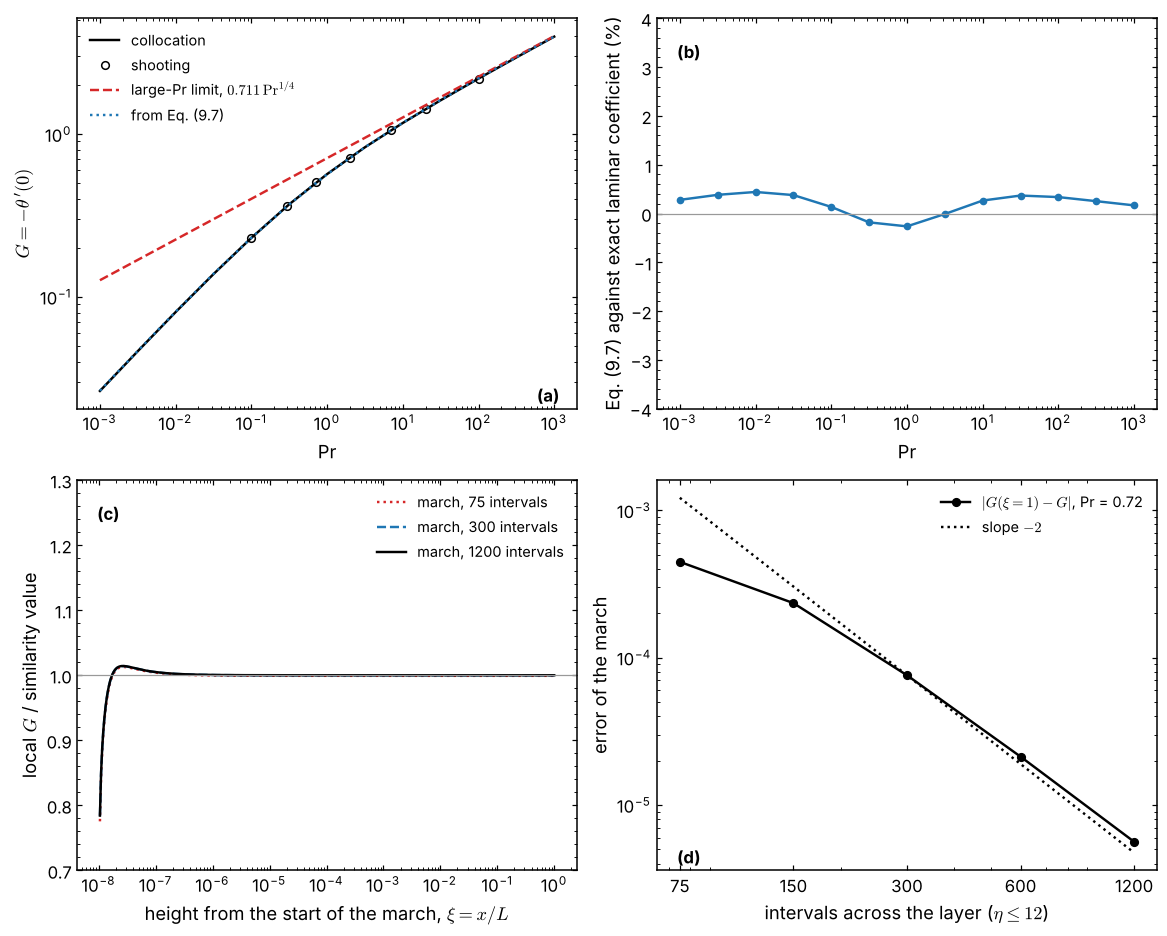

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

ax1.loglog(Prs_wide, G_wide, "k-", label="collocation")
ax1.loglog(Prs_check, G_shoot, "ko", ms=5, mfc="none", label="shooting")
ax1.loglog(Prs_wide, G_large * Prs_wide**0.25, "C3--", label=r"large-Pr limit, $0.711\,\mathrm{Pr}^{1/4}$")
ax1.loglog(Prs_wide, (3 / 4) * cc_coeff * (4 * Prs_wide) ** 0.25, "C0:", label="from Eq. (9.7)")
ax1.set_xlabel("Pr")
ax1.set_ylabel(r"$G = -\theta'(0)$")
ax1.legend(loc="upper left")
panel_label(ax1, "(a)", x=0.92, y=0.06)

ax2.semilogx(Prs_wide, 100 * dev, "C0o-", ms=4)
ax2.axhline(0.0, color="0.6", lw=0.8)
ax2.set_xlabel("Pr")
ax2.set_ylabel("Eq. (9.7) against exact laminar coefficient (%)")
ax2.set_ylim(-4, 4)
panel_label(ax2, "(b)", x=0.04, y=0.94)

for n, style in ((75, "C3:"), (300, "C0--"), (1200, "k-")):
    ax3.semilogx(marches[n]["xi"], marches[n]["G"] / G_air, style, label=f"march, {n} intervals")
ax3.axhline(1.0, color="0.6", lw=0.8)
ax3.set_xlabel(r"height from the start of the march, $\xi = x/L$")
ax3.set_ylabel(r"local $G$ / similarity value")
ax3.set_ylim(0.7, 1.3)
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.94)

ax4.loglog(n_etas, err_march, "ko-", ms=5, label=r"$|G(\xi = 1) - G|$, Pr = 0.72")
ax4.loglog(n_etas, err_march[2] * (np.array(n_etas) / n_etas[2]) ** -2.0, "k:", label="slope $-2$")
ax4.set_xticks(n_etas)
ax4.xaxis.set_major_formatter(plt.ScalarFormatter())
ax4.xaxis.set_minor_formatter(plt.NullFormatter())
ax4.set_xlabel(r"intervals across the layer ($\eta \leq 12$)")
ax4.set_ylabel("error of the march")
ax4.legend(loc="upper right")
panel_label(ax4, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 9.3.** Checks. (a) The wall temperature gradient $G$ against Pr: collocation
(line), shooting (circles), the large-Pr limit, and the value implied by the laminar
correlation (9.7). (b) Deviation of the coefficient of Eq. (9.7) from the exact laminar
one. (c) Local $G$ from the march, which starts from rough profiles at $\xi = 10^{-8}$ and
settles on the similarity value. (d) Error of the march at $\xi = 1$ against the number of
intervals across the layer.

Shooting and collocation agree to $4 \times 10^{-8}$ for $\mathrm{Pr} \le 2$; at
$\mathrm{Pr} = 100$ the difference grows to $10^{-5}$, the error of the shorter domain
the shooting can afford. The march forgets its rough start within a factor of 50 in
height, after which it stays within 0.1 % of the similarity value; its error at $\xi = 1$
falls at second order, to $5 \times 10^{-6}$ with 1200 intervals. The similarity solution
is not only a solution of Eqs. (9.1): a layer started differently tends to it. The laminar
correlation of Churchill and Chu reproduces the exact coefficient to within 0.5 % from
$\mathrm{Pr} = 10^{-3}$ (liquid metals) to $10^3$ (oils); its
uncertainty in practice comes from the experiments, not from the fit.

## 9.7 What to trust

* *The correlations* fit measurements to about ±10 % in the laminar range and ±20 % in the
  turbulent range; transition near $\mathrm{Ra} = 10^9$ depends on disturbances, and the
  full-range formula (9.6) smooths over it.
* *Real enclosures* are not isothermal: the top of a cabinet wall is warmer than the
  bottom, the inside air is warmer than the walls, and the electronics are warmer still.
  The wall limit of 50 °C must be set from the internal temperature drops, which need
  their own model: natural convection of the inside air, and radiation exchange inside
  the enclosure (Chapter 13).
* *Wind* overwhelms natural convection outdoors at a fraction of a metre per second.
  Taking the larger of the forced and natural coefficients, as in Fig. 9.2(d), is a rough
  rule; in between both act together.
* *Radiation* is as large as natural convection in air, so the emissivities and the
  surroundings (a clear night sky, the sun) usually matter more than the convection
  formula; Chapters 12 and 13 treat them properly.
* *Variable properties* are handled by evaluating them at the film temperature, which is
  adequate for temperature differences of tens of kelvin in gases.

## Summary

* Buoyancy drives the flow in natural convection; the boundary-layer equations (9.1) couple
  velocity and temperature, and the Grashof and Rayleigh numbers (9.2) replace the
  Reynolds number.
* The laminar layer on an isothermal vertical plate has Ostrach's similarity solution (9.3),
  with $\mathrm{Nu}_x = G(\mathrm{Pr})(\mathrm{Gr}_x/4)^{1/4}$, Eq. (9.4), and limits (9.5).
* Churchill and Chu's correlations (9.6)–(9.8) cover vertical plates and horizontal
  cylinders from laminar to turbulent; Eq. (9.9) covers the top of a hot plate.
* In air, natural convection coefficients are a few W/(m² K), comparable with radiation;
  a sealed cabinet loses two thirds of its heat by radiation, Eq. (9.10).
* A breeze of a few tenths of a metre per second matches natural convection on a pipe; the
  insulated district-heating pipe loses only 6.5 % less on a calm night.

## Exercises

Sample solutions are in [`solutions/part2_convection/09_solutions.ipynb`](../../solutions/part2_convection/09_solutions.ipynb).

1. **The sun on the cabinet.** At noon in summer the top of the cabinet of Section 9.4
   receives 900 W/m² of sunlight and one side 500 W/m². How much of the cabinet's 620 W
   is used up by the sun if the paint absorbs 60 % of sunlight (grey), and if it absorbs
   25 % (white, with the same infrared emissivity 0.9)? How much power can the electronics
   dissipate in each case with the walls at 50 °C?
2. **A radiator that mostly convects.** A single-panel radiator 0.6 m high and 1.0 m wide
   is at 60 °C in a room at 20 °C whose walls are at 18 °C. Air flows up both faces; only
   the front face (emissivity 0.9) radiates to the room. Find the heat output and the
   fraction that leaves by radiation. Is the layer laminar?
3. **Water against air.** A vertical plate 0.1 m high at 30 °C is immersed in water at
   20 °C (film properties: $k = 0.607$ W/(m K), $\nu = 8.9 \times 10^{-7}$ m²/s,
   $\mathrm{Pr} = 6.1$, $\beta = 2.6 \times 10^{-4}$ 1/K). Find the mean $h$ from the
   similarity solution and from Eq. (9.7), and the thickness of the thermal layer at the
   top (where $\theta = 0.01$). Compare with the same plate in air at 20 °C.
4. **How fast does the air rise?** Using the similarity solution, find the largest upward
   velocity and the thickness of the velocity layer (where $F'$ has fallen to 1 % of its
   maximum) at heights of 0.1 and 0.5 m on the cabinet wall of Section 9.4, while the layer
   is laminar. Compare with the ratio $\mathrm{Gr}_x/\mathrm{Re}_x^2$ for a breeze of
   0.5 m/s blowing up the wall: when does the breeze dominate?

## Suggested references

* S. Ostrach, "An analysis of laminar free-convection flow and heat transfer about a flat
  plate parallel to the direction of the generating body force", NACA Report 1111 (1953).
* S. W. Churchill and H. H. S. Chu, "Correlating equations for laminar and turbulent free
  convection from a vertical plate", *Int. J. Heat Mass Transfer* **18**, 1323 (1975).
* S. W. Churchill and H. H. S. Chu, "Correlating equations for laminar and turbulent free
  convection from a horizontal cylinder", *Int. J. Heat Mass Transfer* **18**, 1049 (1975).
* J. R. Lloyd and W. R. Moran, "Natural convection adjacent to horizontal surface of
  various planforms", *J. Heat Transfer* **96**, 443 (1974).
* B. Gebhart, Y. Jaluria, R. L. Mahajan and B. Sammakia, *Buoyancy-Induced Flows and
  Transport* (Hemisphere, 1988).

---

**Previous:** [8. Internal flow and the Graetz problem](08_internal_flow.ipynb) &nbsp;·&nbsp; **Next:** [10. Boiling and condensation](10_boiling_condensation.ipynb)